# Uber Fare Prediction: Exploratory Data Analysis and Machine Learning

#### Project Title : Uber Fare Prediction
#### Institute : VijAI Robotics Pvt. Ltd.
#### Mentor : Dr. Arvind Joshi, Chief Data Scientist
#### Role : AI Engineer Intern

## Project Overview

This project explores an Uber fare dataset containing trip details, pickup and drop-off coordinates, pickup date and time, and passenger count. The analysis focuses on understanding the factors associated with fare variation and using these findings to build a fare prediction model.

The project includes exploratory data analysis, data cleaning, feature engineering, regression model comparison, and a Streamlit application for making predictions.

## My Objective

My objective is to develop practical data science skills by working with a real-world trip dataset. I want to understand how to explore raw data, identify quality issues, extract meaningful insights, engineer useful features, and build a machine learning model that can estimate trip fares. I also aim to present the results clearly and make the trained model accessible through a simple web application.

## Project Objectives

- Understand the structure and characteristics of the Uber fare dataset.
- Perform univariate, bivariate, and multivariate analysis.
- Identify missing values, duplicate records, invalid values, and potential outliers.
- Explore the relationship between fare amount, trip distance, pickup time, and passenger count.
- Create useful features from trip coordinates and pickup datetime.
- Train and compare regression models using MAE, RMSE, and R².
- Save the selected model and integrate it into a Streamlit application.
- Document findings, limitations, and possible improvements.

## Literature Review

Fare prediction is a regression problem because the goal is to estimate a continuous numerical value. Previous work in taxi fare prediction has shown the importance of understanding trip distance, pickup time, geographic coordinates, and data quality before developing a predictive model.

The New York City Taxi and Limousine Commission publishes trip record data that can help researchers understand taxi journeys and travel patterns. Such datasets demonstrate how trip information can be used for transportation analysis.

Research and documentation on machine learning also emphasize that data preprocessing, feature engineering, proper train-test splitting, and suitable evaluation metrics are essential for building reliable predictive models.

In this project, these ideas are applied to an Uber fare dataset. Trip distance is calculated from pickup and drop-off coordinates using the Haversine formula. Pickup date and time are converted into useful features, and regression algorithms are evaluated using MAE, RMSE, and R².

## What I Learned from the Literature Review

- Fare prediction is a regression problem because the target is a continuous numerical value.
- Trip distance is an important candidate feature for estimating fares.
- Pickup time may help capture differences in travel patterns.
- Raw geographic coordinates need to be checked for missing and invalid values.
- Outliers should be investigated before deciding whether to remove them.
- Feature engineering can make raw trip data more useful for machine learning.
- Train-test splitting helps evaluate how well a model performs on unseen data.
- MAE and RMSE measure prediction errors, while R² measures the proportion of target variance explained by the model.
- Different regression algorithms can perform differently on the same dataset.
- A model should be evaluated on held-out data before being used for real-world predictions.

## Understanding of Dataset Columns

The dataset contains trip-level information that can help explain differences in fare amounts.

| Column | Description | Purpose |
|---|---|---|
| `Unnamed: 0` | An index-like column added during data export | Usually unnecessary for prediction |
| `key` | Unique trip identifier or record key | Identification; generally excluded from model features |
| `fare_amount` | Recorded fare amount for the trip | Target variable |
| `pickup_datetime` | Date and time when the trip started | Used to extract time-based features |
| `pickup_longitude` | Longitude of the pickup location | Geographic information |
| `pickup_latitude` | Latitude of the pickup location | Geographic information |
| `dropoff_longitude` | Longitude of the drop-off location | Geographic information |
| `dropoff_latitude` | Latitude of the drop-off location | Geographic information |
| `passenger_count` | Number of passengers recorded for the trip | Potential predictive feature |

### Additional Features Created

| Feature | Description |
|---|---|
| `distance_km` | Approximate straight-line distance between pickup and drop-off |
| `pickup_hour` | Hour of the day when the trip started |
| `pickup_day` | Day of the month |
| `pickup_month` | Month of the year |
| `pickup_dayofweek` | Day of the week, represented from 0 to 6 |

**Target variable:** `fare_amount`

**Machine learning task:** Supervised regression.

The exact meaning and units of the fare should be confirmed from the original dataset documentation.

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [68]:
df = pd.read_csv(r"D:\EDA projects\Uber-Analysis\data\uber.csv")

# Data Understanding

In [69]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [70]:
df.shape

(200000, 9)

In [71]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB


In [72]:
df.columns

Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='str')

In [73]:
df.dtypes

Unnamed: 0             int64
key                      str
fare_amount          float64
pickup_datetime          str
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object

In [74]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [75]:
df.describe(include='object')

,key,pickup_datetime
count,200000,200000
unique,200000,196629
top,2015-05-07 19:52:06.0000003,2009-02-12 12:46:00 UTC
freq,1,4


## Missing values

In [76]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [77]:
df.duplicated().sum()

np.int64(0)

# Univariate Analysis

## Fare amount Distribution

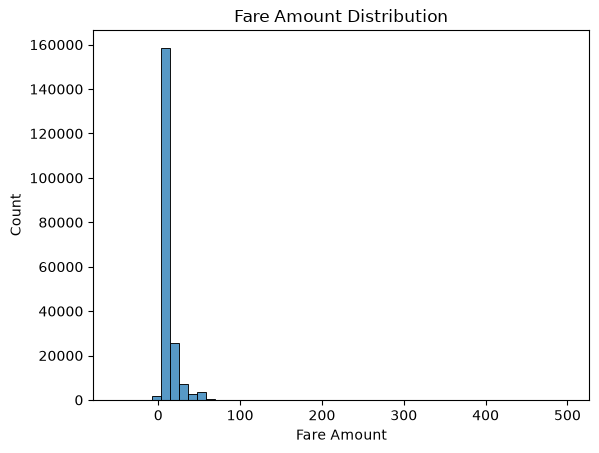

In [78]:
sns.histplot(df["fare_amount"], bins=50)
plt.title("Fare Amount Distribution")
plt.xlabel("Fare Amount")
plt.ylabel("Count")
plt.show()

### Insights

Most Uber trips seem to fall within a certain fare range, while a few trips have much higher fares. This suggests that trip costs vary considerably, possible because of differences in travel distance.

## Fare Amount Outliers

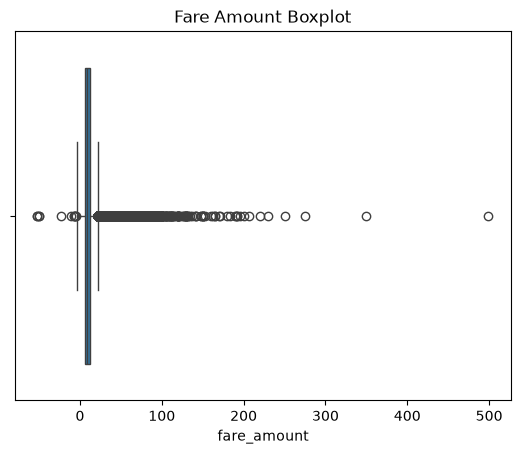

In [79]:
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Amount Boxplot")
plt.show()

### Insights

The boxplot shows that some trips have fares much higher or lower than typical range. These points may represent usually long trips, incorrect entries or other special cases.

## Passenger Count Distribution

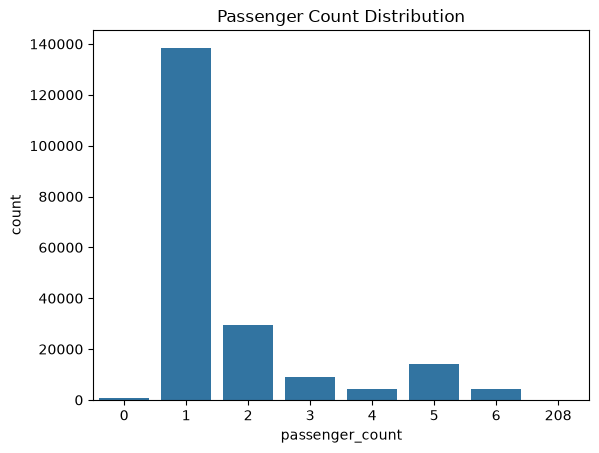

In [80]:
sns.countplot(x=df["passenger_count"])
plt.title("Passenger Count Distribution")
plt.show()

### Insights

Most uber trips appear to have a small number of passengers, which make sense for everyday rides. Trips with higher passenger counts are less common. This pattern can help us understand the usage of the service.

## Pickup Datetime Analysis

In [81]:
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
df["pickup_datetime"].head()

0   2015-05-07 19:52:06+00:00
1   2009-07-17 20:04:56+00:00
2   2009-08-24 21:45:00+00:00
3   2009-06-26 08:22:21+00:00
4   2014-08-28 17:47:00+00:00
Name: pickup_datetime, dtype: datetime64[us, UTC]

## Pickup Hour Distribution

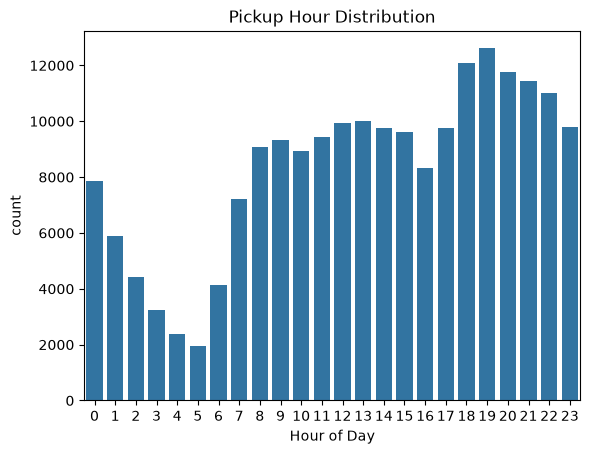

In [82]:
df["pickup_hour"] = df["pickup_datetime"].dt.hour

sns.countplot(x=df["pickup_hour"])
plt.title("Pickup Hour Distribution")
plt.xlabel("Hour of Day")
plt.show()

### Insights

The number of trips varies throughout the day, suggesting that ride demand may depend on people's daily routines. Certain hours may be busier than others due to work, travel, or other activities.

# Bivariate Analysis

## Fare Amount Vs Passenger Count

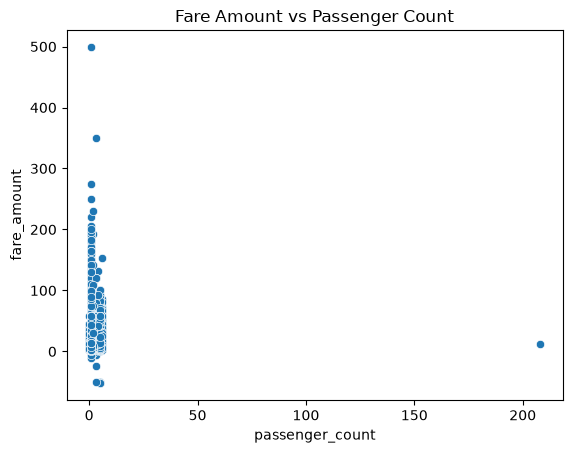

In [83]:
sns.scatterplot(data=df, x="passenger_count", y="fare_amount")
plt.title("Fare Amount vs Passenger Count")
plt.show()

### Insights

The scatter plot does not necessarily show a clear relationship between passenger count and fare amount. Trips with different passenger counts can have similar fares, suggesting that the number of passengers alone may not explain the trip cost.

## Fare Amount Vs Pickup Hour

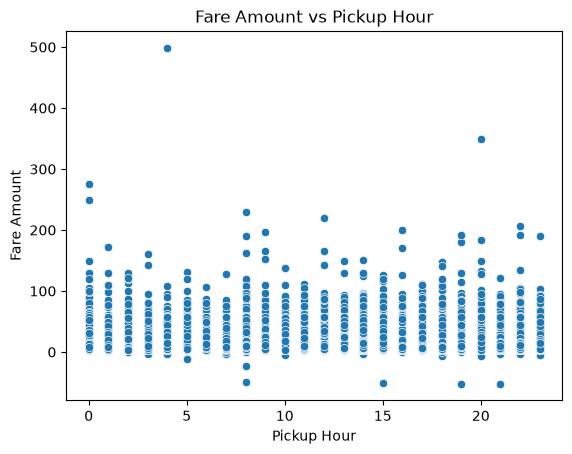

In [84]:
sns.scatterplot(data=df, x="pickup_hour", y="fare_amount")
plt.title("Fare Amount vs Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Fare Amount")
plt.show()

### Insights

The fare amount vary across different pickup hours, but there may not be a clear pattern from time alone. Some hours show a wider range of fares than others. This suggests that pickup time should be considered.

## Fare Amount Vs Trip Distance

In [85]:
from math import radians, sin, cos, asin, sqrt

def distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    return 6371 * 2 * asin(sqrt(a))

df["distance_km"] = df.apply(
    lambda row: distance(
        row["pickup_latitude"],
        row["pickup_longitude"],
        row["dropoff_latitude"],
        row["dropoff_longitude"]
    ),
    axis=1
)

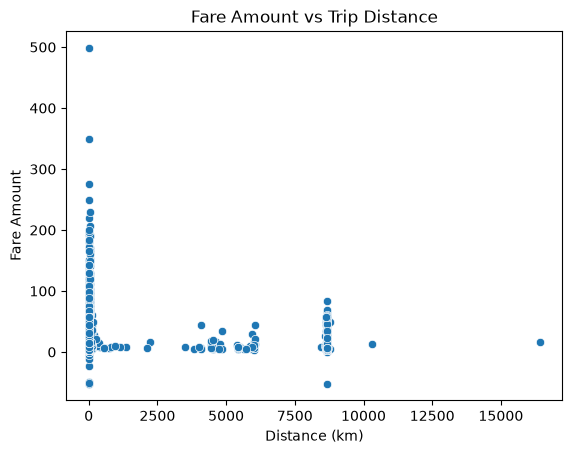

In [86]:
sns.scatterplot(data=df, x="distance_km", y="fare_amount")
plt.title("Fare Amount vs Trip Distance")
plt.xlabel("Distance (km)")
plt.ylabel("Fare Amount")
plt.show()

### Insights

The plot suggests that fares generally increase a trip distance increases, although some trips do not follow this pattern. This makes sense because longer trips usually involve higher travel costs. 

## Average Fare by Pickup Hour

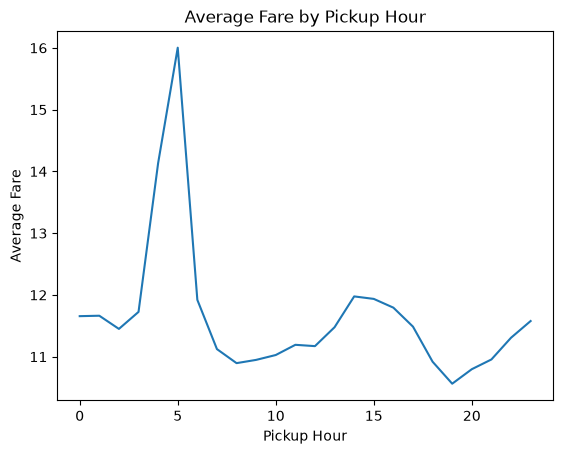

In [87]:
df.groupby("pickup_hour")["fare_amount"].mean().plot(kind="line")

plt.title("Average Fare by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Average Fare")
plt.show()

### Insights

The average fare changes across different pickup hours, but time alone may not explain these differnces. Some hours may include longer trips, which can increase the average fare. 

## Fare Distribution by Passenger Count

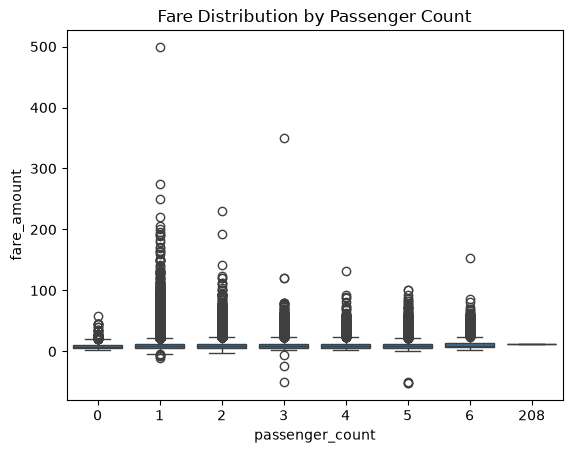

In [88]:
sns.boxplot(data=df, x="passenger_count", y="fare_amount")
plt.title("Fare Distribution by Passenger Count")
plt.show()

### Insights

The fare distributions across passenger counts appear to overlap, suggesting that the number of passengers may not have a strong influence on the fare by itself. Some groups may contain extreme fares than others, but these differnces could be related to trip distance.

# Multivariate Analysis

## Correlation Heatmap

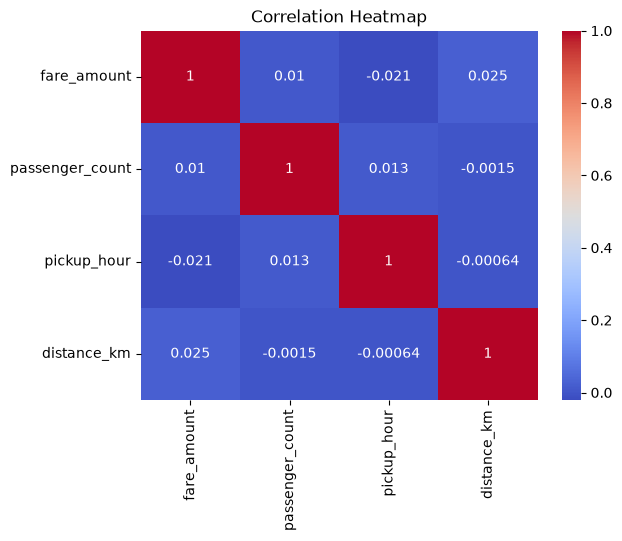

In [89]:
sns.heatmap(
    df[["fare_amount", "passenger_count", "pickup_hour", "distance_km"]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

### Insights

The heatmap helps us understand how the numerical features are related to each other. Trip distance is expected to be an important factor in fare prediction, while passenger count and pickup hour may show weaker linear relationships with fare.

# Outlier Analysis

Fare Outliers: 17167


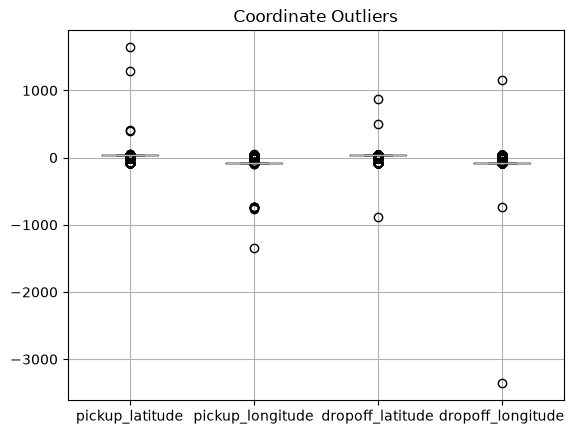

pickup_latitude invalid: 4
pickup_longitude invalid: 7
dropoff_latitude invalid: 3
dropoff_longitude invalid: 3
Trips with both locations in NYC range: 195580
Trips outside this approximate range: 4420

Coordinate Summary:
       pickup_latitude  pickup_longitude  dropoff_latitude  dropoff_longitude
count    200000.000000     200000.000000     199999.000000      199999.000000
mean         39.935885        -72.527638         39.923890         -72.525292
std           7.720539         11.437787          6.794829          13.117408
min         -74.015515      -1340.648410       -881.985513       -3356.666300
25%          40.734796        -73.992065         40.733823         -73.991407
50%          40.752592        -73.981823         40.753042         -73.980093
75%          40.767158        -73.967154         40.768001         -73.963658
max        1644.421482         57.418457        872.697628        1153.572603


In [94]:
# 1. Fare Amount Outliers (IQR)
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Fare Outliers:", ((df["fare_amount"] < lower) |
                         (df["fare_amount"] > upper)).sum())

# 2. Coordinate Outliers (Boxplots)
df[["pickup_latitude", "pickup_longitude",
    "dropoff_latitude", "dropoff_longitude"]].boxplot()
plt.title("Coordinate Outliers")
plt.show()

# 3. Invalid Geographic Ranges
for col, low, high in [
    ("pickup_latitude", -90, 90),
    ("pickup_longitude", -180, 180),
    ("dropoff_latitude", -90, 90),
    ("dropoff_longitude", -180, 180)
]:
    print(f"{col} invalid:", ((df[col] < low) | (df[col] > high)).sum())

# 4. New York Geographic Range Check
nyc = (
    df["pickup_latitude"].between(40.5, 41.0) &
    df["pickup_longitude"].between(-74.3, -73.7) &
    df["dropoff_latitude"].between(40.5, 41.0) &
    df["dropoff_longitude"].between(-74.3, -73.7)
)

print("Trips with both locations in NYC range:", nyc.sum())
print("Trips outside this approximate range:", (~nyc).sum())

# 5. Coordinate Summary
print("\nCoordinate Summary:")
print(df[["pickup_latitude", "pickup_longitude",
          "dropoff_latitude", "dropoff_longitude"]].describe())

### Insights 

The outlier analysis highlights trips with unusually high or low fares and some extreme coordinate values. These observations may come from genuine unusual trips or data quality issues

## Overall Key Insights

1. **Fare Variation:** Fare amounts vary considerably across trips, indicating that trips do not all have similar costs.

2. **Fare Outliers:** Some trips have unusually high or low fares. These observations need investigation before deciding whether they are errors or valid trips.

3. **Passenger Count:** Most rides appear to involve relatively few passengers. Passenger count alone may not explain differences in fare amounts.

4. **Pickup Time Patterns:** Ride frequency varies across pickup hours, suggesting that trip demand may follow daily travel patterns.

5. **Distance and Fare:** Trip distance is an important factor to investigate because longer journeys generally involve higher fares.

6. **Time and Fare:** Pickup time may provide additional information, but its relationship with fare should be evaluated alongside distance and other trip characteristics.

7. **Geographic Data Quality:** Pickup and drop-off coordinates require validation because incorrect locations can produce misleading distance calculations.

8. **Correlation Limitations:** Correlation analysis helps identify linear relationships, but weak correlation does not necessarily mean a feature is useless for prediction.

9. **Feature Engineering:** Creating distance and datetime features makes raw trip information more useful for regression models.

10. **Model Evaluation:** Comparing regression models using MAE, RMSE, and R² helps assess prediction performance. The final model should be selected based on measured performance rather than assumptions about which algorithm is best.

## References

1. **Kaggle — New York City Taxi Fare Prediction**  
   https://www.kaggle.com/competitions/new-york-city-taxi-fare-prediction  
   Used as a reference for the taxi fare prediction problem and dataset context.

2. **New York City Taxi and Limousine Commission — Trip Record Data**  
   https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page  
   Provides background on taxi trip data and transportation analysis.

3. **Scikit-learn — Supervised Learning**  
   https://scikit-learn.org/stable/supervised_learning.html  
   Reference for regression algorithms and supervised machine learning.

4. **Scikit-learn — Model Evaluation**  
   https://scikit-learn.org/stable/modules/model_evaluation.html  
   Reference for evaluation metrics and model assessment.

5. **Pandas Documentation**  
   https://pandas.pydata.org/docs/  
   Reference for data loading, cleaning, manipulation, and datetime operations.

6. **Scikit-learn — Train-Test Split**  
   https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html  
   Reference for splitting data into training and testing sets.

7. **Movable Type Scripts — Calculate Distance Between Two Points on Earth**  
   https://www.movable-type.co.uk/scripts/latlong.html  
   Reference for geographic distance calculations, including the Haversine formula.


## Use of Large Language Models (LLMs)

A large language model (LLM) was used as a supporting tool during project development. It helped explain Python code, suggest EDA approaches, assist with debugging, and organize notebook sections and written insights.

The analysis, data cleaning, model training, and evaluation were carried out using Python libraries. LLM-generated suggestions were treated as assistance rather than verified findings, and interpretations should be checked against the actual dataset and visualizations.

The LLM supported the learning process, while the final conclusions should be based on the results obtained from the data and trained models.

## Conclusion

This project provided an opportunity to explore Uber fare data and understand the steps involved in building a machine learning solution. Exploratory data analysis helped examine fare distributions, passenger counts, pickup times, trip distances, and potential data quality issues.

Feature engineering converted raw trip information into useful inputs for regression models. Linear Regression, Random Forest Regressor, and Gradient Boosting Regressor were trained and compared using appropriate evaluation metrics. The selected model was saved and integrated into a Streamlit application that allows users to enter trip details and receive an estimated fare.

The project demonstrates the complete basic workflow from data exploration to a working prediction interface. However, the predictions should not be treated as official Uber quotes. Further improvements could include hyperparameter tuning, more careful geographic validation, stronger feature engineering, and testing on additional unseen data.